In [3]:

# Clone the official ETDataset repository
!git clone https://github.com/zhouhaoyi/ETDataset.git

# Check the dataset files
import os

dataset_path = "/content/ETDataset/ETT-small/ETTh1.csv"

print("Dataset exists:", os.path.exists(dataset_path))


Cloning into 'ETDataset'...
remote: Enumerating objects: 187, done.
remote: Counting objects: 100% (30/30), done.
remote: Compressing objects: 100% (10/10), done.
remote: Total 187 (delta 26), reused 20 (delta 20), pack-reused 157 (from 1)
Receiving objects: 100% (187/187), 3.86 MiB | 11.31 MiB/s, done.
Resolving deltas: 100% (62/62), done.
Dataset exists: True


In [4]:

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.preprocessing import StandardScaler
from sklearn.metrics import mean_squared_error, mean_absolute_error

import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader

print("All libraries imported successfully!")
print("GPU Available:", torch.cuda.is_available())


All libraries imported successfully!
GPU Available: True


In [5]:

# Load dataset
df = pd.read_csv(dataset_path)

# Display first five rows
display(df.head())

# Dataset dimensions
print("Dataset Shape:", df.shape)

# Column names
print("\nColumns:")
print(df.columns.tolist())

# Check missing values
print("\nMissing Values:")
print(df.isnull().sum())


,date,HUFL,HULL,MUFL,MULL,LUFL,LULL,OT
0,2016-07-01 00:00:00,5.827,2.009,1.599,0.462,4.203,1.340,30.531000
1,2016-07-01 01:00:00,5.693,2.076,1.492,0.426,4.142,1.371,27.787001
2,2016-07-01 02:00:00,5.157,1.741,1.279,0.355,3.777,1.218,27.787001
3,2016-07-01 03:00:00,5.090,1.942,1.279,0.391,3.807,1.279,25.044001
4,2016-07-01 04:00:00,5.358,1.942,1.492,0.462,3.868,1.279,21.948000


Dataset Shape: (17420, 8)

Columns:
['date', 'HUFL', 'HULL', 'MUFL', 'MULL', 'LUFL', 'LULL', 'OT']

Missing Values:
date    0
HUFL    0
HULL    0
MUFL    0
MULL    0
LUFL    0
LULL    0
OT      0
dtype: int64


In [6]:

# Dataset information
df.info()

# Statistical summary
display(df.describe())

# Check data types
print(df.dtypes)


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 17420 entries, 0 to 17419
Data columns (total 8 columns):
 #   Column  Non-Null Count  Dtype  
---  ------  --------------  -----  
 0   date    17420 non-null  object 
 1   HUFL    17420 non-null  float64
 2   HULL    17420 non-null  float64
 3   MUFL    17420 non-null  float64
 4   MULL    17420 non-null  float64
 5   LUFL    17420 non-null  float64
 6   LULL    17420 non-null  float64
 7   OT      17420 non-null  float64
dtypes: float64(7), object(1)
memory usage: 1.1+ MB


,HUFL,HULL,MUFL,MULL,LUFL,LULL,OT
count,17420.000000,17420.000000,17420.000000,17420.000000,17420.000000,17420.000000,17420.000000
mean,7.375141,2.242242,4.300239,0.881568,3.066062,0.856932,13.324672
std,7.067744,2.042342,6.826978,1.809293,1.164506,0.599552,8.566946
min,-22.705999,-4.756000,-25.087999,-5.934000,-1.188000,-1.371000,-4.080000
25%,5.827000,0.737000,3.296000,-0.284000,2.315000,0.670000,6.964000
50%,8.774000,2.210000,5.970000,0.959000,2.833000,0.975000,11.396000
75%,11.788000,3.684000,8.635000,2.203000,3.625000,1.218000,18.079000
max,23.643999,10.114000,17.341000,7.747000,8.498000,3.046000,46.007000


date     object
HUFL    float64
HULL    float64
MUFL    float64
MULL    float64
LUFL    float64
LULL    float64
OT      float64
dtype: object


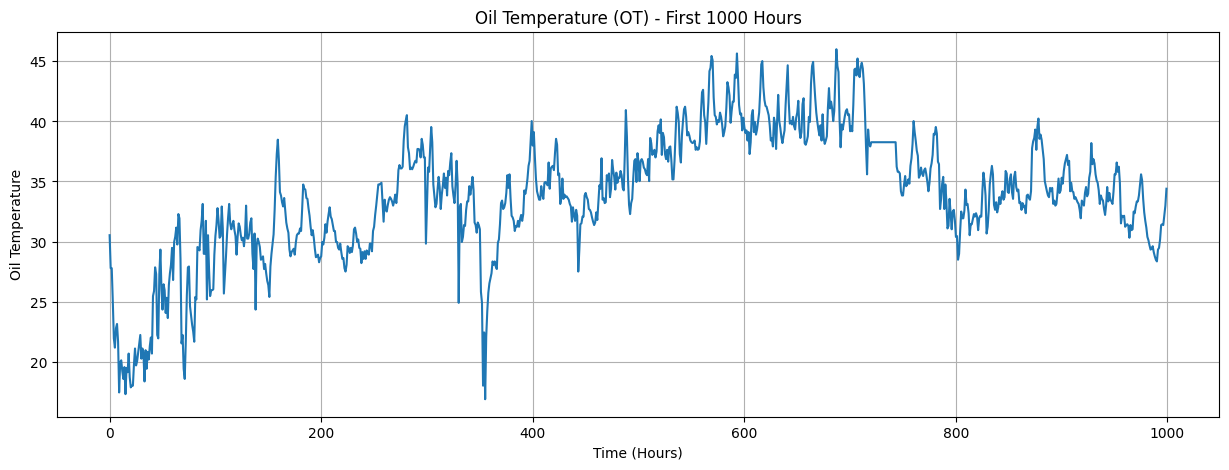

In [7]:

plt.figure(figsize=(15, 5))

plt.plot(df['OT'][:1000])

plt.title("Oil Temperature (OT) - First 1000 Hours")
plt.xlabel("Time (Hours)")
plt.ylabel("Oil Temperature")
plt.grid(True)

plt.show()


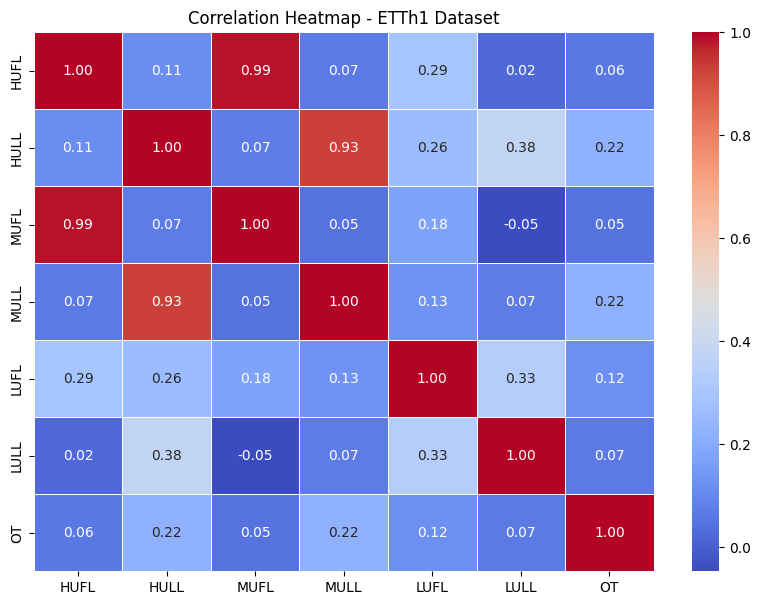

In [8]:

# Calculate correlation between numerical variables
correlation = df.drop(columns=['date']).corr()

plt.figure(figsize=(10, 7))

sns.heatmap(
    correlation,
    annot=True,
    cmap='coolwarm',
    fmt='.2f',
    linewidths=0.5
)

plt.title("Correlation Heatmap - ETTh1 Dataset")
plt.show()


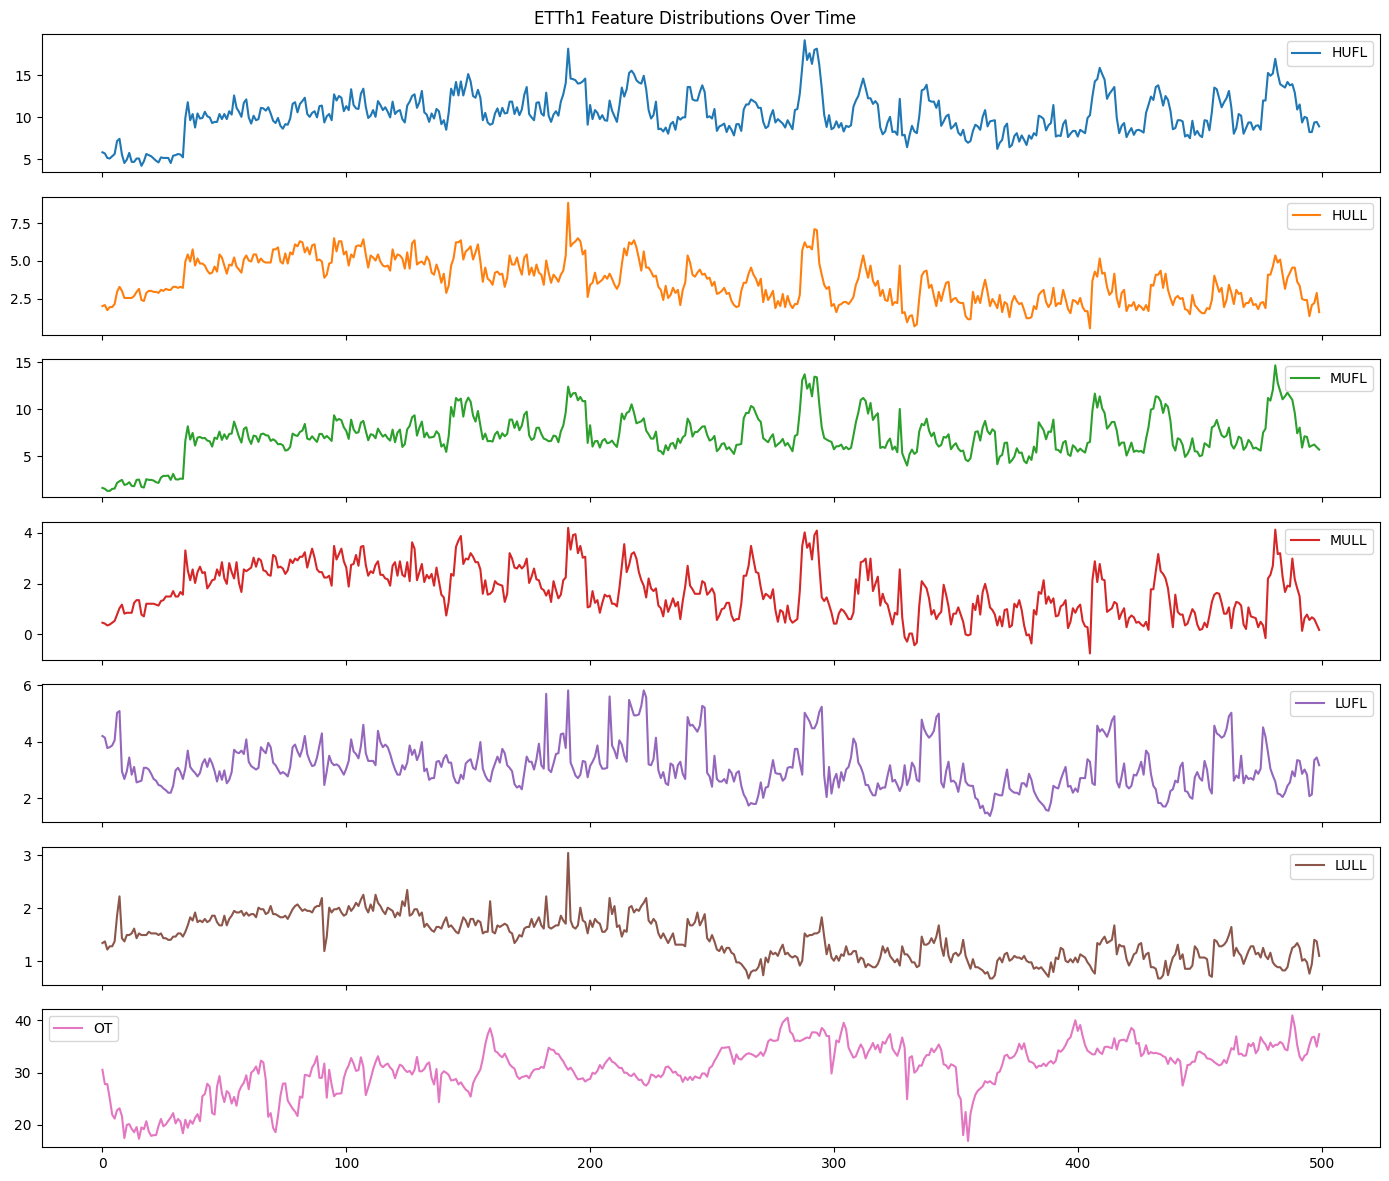

In [9]:

features = ['HUFL', 'HULL', 'MUFL', 'MULL', 'LUFL', 'LULL', 'OT']

df[features][:500].plot(
    subplots=True,
    figsize=(14, 12),
    title="ETTh1 Feature Distributions Over Time"
)

plt.tight_layout()
plt.show()


In [10]:

# Convert date column
df['date'] = pd.to_datetime(df['date'])

# Sort chronologically
df = df.sort_values('date').reset_index(drop=True)

# Select input features
feature_columns = [
    'HUFL', 'HULL', 'MUFL',
    'MULL', 'LUFL', 'LULL', 'OT'
]

# Prediction target
target_column = 'OT'

# Extract numerical data
data = df[feature_columns].values

print("Prepared data shape:", data.shape)
print("Target variable:", target_column)


Prepared data shape: (17420, 7)
Target variable: OT


In [11]:

total_size = len(data)

train_end = int(total_size * 0.70)
val_end = int(total_size * 0.80)

train_data = data[:train_end]
val_data = data[train_end:val_end]
test_data = data[val_end:]

print("Training samples:", len(train_data))
print("Validation samples:", len(val_data))
print("Testing samples:", len(test_data))


Training samples: 12194
Validation samples: 1742
Testing samples: 3484


In [12]:

scaler = StandardScaler()

# Fit only on training data to prevent data leakage
scaler.fit(train_data)

train_scaled = scaler.transform(train_data)
val_scaled = scaler.transform(val_data)
test_scaled = scaler.transform(test_data)

print("Normalization completed!")
print("Training shape:", train_scaled.shape)
print("Validation shape:", val_scaled.shape)
print("Testing shape:", test_scaled.shape)


Normalization completed!
Training shape: (12194, 7)
Validation shape: (1742, 7)
Testing shape: (3484, 7)


In [13]:

# Sequence configuration
sequence_length = 96
prediction_length = 24

target_index = feature_columns.index('OT')

# Transform the complete dataset using the training-fitted scaler
all_scaled = scaler.transform(data)

def create_sequences(data, start, end,
                     seq_len=96, pred_len=24):

    X, y = [], []

    for i in range(start, end - pred_len + 1):

        # Historical input
        X.append(data[i-seq_len:i, :])

        # Future oil temperature
        y.append(
            data[i:i+pred_len, target_index]
        )

    return np.array(X), np.array(y)


# Training sequences
X_train, y_train = create_sequences(
    all_scaled,
    sequence_length,
    train_end
)

# Validation sequences
X_val, y_val = create_sequences(
    all_scaled,
    train_end,
    val_end
)

# Testing sequences
X_test, y_test = create_sequences(
    all_scaled,
    val_end,
    total_size
)

print("Sequence generation completed!")
print("X_train:", X_train.shape)
print("y_train:", y_train.shape)
print("X_val:", X_val.shape)
print("y_val:", y_val.shape)
print("X_test:", X_test.shape)
print("y_test:", y_test.shape)


Sequence generation completed!
X_train: (12075, 96, 7)
y_train: (12075, 24)
X_val: (1719, 96, 7)
y_val: (1719, 24)
X_test: (3461, 96, 7)
y_test: (3461, 24)


In [14]:

# Convert NumPy arrays into PyTorch tensors

X_train_tensor = torch.tensor(X_train, dtype=torch.float32)
y_train_tensor = torch.tensor(y_train, dtype=torch.float32)

X_val_tensor = torch.tensor(X_val, dtype=torch.float32)
y_val_tensor = torch.tensor(y_val, dtype=torch.float32)

X_test_tensor = torch.tensor(X_test, dtype=torch.float32)
y_test_tensor = torch.tensor(y_test, dtype=torch.float32)

print("PyTorch tensor conversion completed!")

print("Training tensor:", X_train_tensor.shape)
print("Validation tensor:", X_val_tensor.shape)
print("Testing tensor:", X_test_tensor.shape)


PyTorch tensor conversion completed!
Training tensor: torch.Size([12075, 96, 7])
Validation tensor: torch.Size([1719, 96, 7])
Testing tensor: torch.Size([3461, 96, 7])


In [15]:

from torch.utils.data import TensorDataset, DataLoader

batch_size = 64

train_dataset = TensorDataset(
    X_train_tensor, y_train_tensor
)

val_dataset = TensorDataset(
    X_val_tensor, y_val_tensor
)

test_dataset = TensorDataset(
    X_test_tensor, y_test_tensor
)

train_loader = DataLoader(
    train_dataset,
    batch_size=batch_size,
    shuffle=True
)

val_loader = DataLoader(
    val_dataset,
    batch_size=batch_size,
    shuffle=False
)

test_loader = DataLoader(
    test_dataset,
    batch_size=batch_size,
    shuffle=False
)

print("DataLoaders created successfully!")
print("Training batches:", len(train_loader))
print("Validation batches:", len(val_loader))
print("Testing batches:", len(test_loader))


DataLoaders created successfully!
Training batches: 189
Validation batches: 27
Testing batches: 55


In [16]:

device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

print("Training device:", device)


Training device: cuda


In [17]:

class BaselineLSTM(nn.Module):

    def __init__(self, input_size=7,
                 hidden_size=128,
                 num_layers=2,
                 output_size=24,
                 dropout=0.2):

        super(BaselineLSTM, self).__init__()

        self.lstm = nn.LSTM(
            input_size=input_size,
            hidden_size=hidden_size,
            num_layers=num_layers,
            batch_first=True,
            dropout=dropout
        )

        self.fc = nn.Linear(
            hidden_size,
            output_size
        )

    def forward(self, x):

        output, (hidden, cell) = self.lstm(x)

        # Use the final time-step representation
        last_output = output[:, -1, :]

        prediction = self.fc(last_output)

        return prediction


# Initialize model
baseline_model = BaselineLSTM().to(device)

print(baseline_model)


BaselineLSTM(
  (lstm): LSTM(7, 128, num_layers=2, batch_first=True, dropout=0.2)
  (fc): Linear(in_features=128, out_features=24, bias=True)
)


In [18]:

criterion = nn.MSELoss()

optimizer = torch.optim.Adam(
    baseline_model.parameters(),
    lr=0.001
)

print("Loss function:", criterion)
print("Optimizer:", optimizer)


Loss function: MSELoss()
Optimizer: Adam (
Parameter Group 0
    amsgrad: False
    betas: (0.9, 0.999)
    capturable: False
    decoupled_weight_decay: False
    differentiable: False
    eps: 1e-08
    foreach: None
    fused: None
    lr: 0.001
    maximize: False
    weight_decay: 0
)


In [19]:

import copy

epochs = 30
patience = 5

train_losses = []
val_losses = []

best_val_loss = float('inf')
best_model_weights = None
epochs_without_improvement = 0

for epoch in range(epochs):

    # Training phase
    baseline_model.train()
    running_train_loss = 0.0

    for X_batch, y_batch in train_loader:

        X_batch = X_batch.to(device)
        y_batch = y_batch.to(device)

        optimizer.zero_grad()

        predictions = baseline_model(X_batch)

        loss = criterion(predictions, y_batch)

        loss.backward()

        torch.nn.utils.clip_grad_norm_(
            baseline_model.parameters(), max_norm=1.0
        )

        optimizer.step()

        running_train_loss += loss.item()

    epoch_train_loss = running_train_loss / len(train_loader)

    # Validation phase
    baseline_model.eval()
    running_val_loss = 0.0

    with torch.no_grad():

        for X_batch, y_batch in val_loader:

            X_batch = X_batch.to(device)
            y_batch = y_batch.to(device)

            predictions = baseline_model(X_batch)

            loss = criterion(predictions, y_batch)

            running_val_loss += loss.item()

    epoch_val_loss = running_val_loss / len(val_loader)

    train_losses.append(epoch_train_loss)
    val_losses.append(epoch_val_loss)

    print(
        f"Epoch [{epoch+1}/{epochs}] "
        f"Train Loss: {epoch_train_loss:.6f} "
        f"Val Loss: {epoch_val_loss:.6f}"
    )

    # Save best model
    if epoch_val_loss < best_val_loss:

        best_val_loss = epoch_val_loss
        best_model_weights = copy.deepcopy(
            baseline_model.state_dict()
        )

        epochs_without_improvement = 0

    else:
        epochs_without_improvement += 1

    # Early stopping
    if epochs_without_improvement >= patience:

        print("Early stopping activated!")
        break

# Restore best model
baseline_model.load_state_dict(best_model_weights)

print("\nBaseline LSTM training completed!")
print("Best validation loss:", best_val_loss)


Epoch [1/30] Train Loss: 0.191985 Val Loss: 0.190459
Epoch [2/30] Train Loss: 0.100701 Val Loss: 0.092756
Epoch [3/30] Train Loss: 0.091516 Val Loss: 0.080062
Epoch [4/30] Train Loss: 0.086382 Val Loss: 0.047431
Epoch [5/30] Train Loss: 0.083540 Val Loss: 0.108258
Epoch [6/30] Train Loss: 0.078204 Val Loss: 0.154762
Epoch [7/30] Train Loss: 0.076029 Val Loss: 0.227311
Epoch [8/30] Train Loss: 0.072508 Val Loss: 0.284793
Epoch [9/30] Train Loss: 0.068184 Val Loss: 0.175485
Early stopping activated!

Baseline LSTM training completed!
Best validation loss: 0.047431368208317844


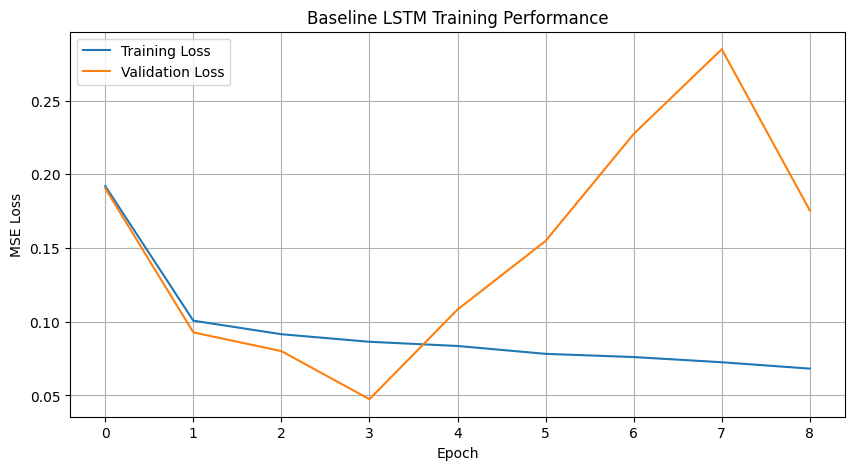

In [20]:

plt.figure(figsize=(10, 5))

plt.plot(train_losses, label='Training Loss')
plt.plot(val_losses, label='Validation Loss')

plt.title("Baseline LSTM Training Performance")
plt.xlabel("Epoch")
plt.ylabel("MSE Loss")

plt.legend()
plt.grid(True)
plt.show()


In [21]:

baseline_model.eval()

predictions_list = []
actual_list = []

with torch.no_grad():

    for X_batch, y_batch in test_loader:

        X_batch = X_batch.to(device)

        predictions = baseline_model(X_batch)

        predictions_list.append(
            predictions.cpu().numpy()
        )

        actual_list.append(
            y_batch.numpy()
        )

y_pred = np.concatenate(predictions_list, axis=0)
y_actual = np.concatenate(actual_list, axis=0)

print("Predictions shape:", y_pred.shape)
print("Actual values shape:", y_actual.shape)


Predictions shape: (3461, 24)
Actual values shape: (3461, 24)


In [22]:

# Convert normalized values back to original scale

target_mean = scaler.mean_[target_index]
target_std = scaler.scale_[target_index]

y_pred_original = y_pred * target_std + target_mean
y_actual_original = y_actual * target_std + target_mean

# Evaluation metrics
mse = mean_squared_error(
    y_actual_original.flatten(),
    y_pred_original.flatten()
)

mae = mean_absolute_error(
    y_actual_original.flatten(),
    y_pred_original.flatten()
)

rmse = np.sqrt(mse)

print("BASELINE LSTM RESULTS")
print("----------------------")
print("MSE :", round(mse, 4))
print("MAE :", round(mae, 4))
print("RMSE:", round(rmse, 4))


BASELINE LSTM RESULTS
----------------------
MSE : 3.1976
MAE : 1.3569
RMSE: 1.7882


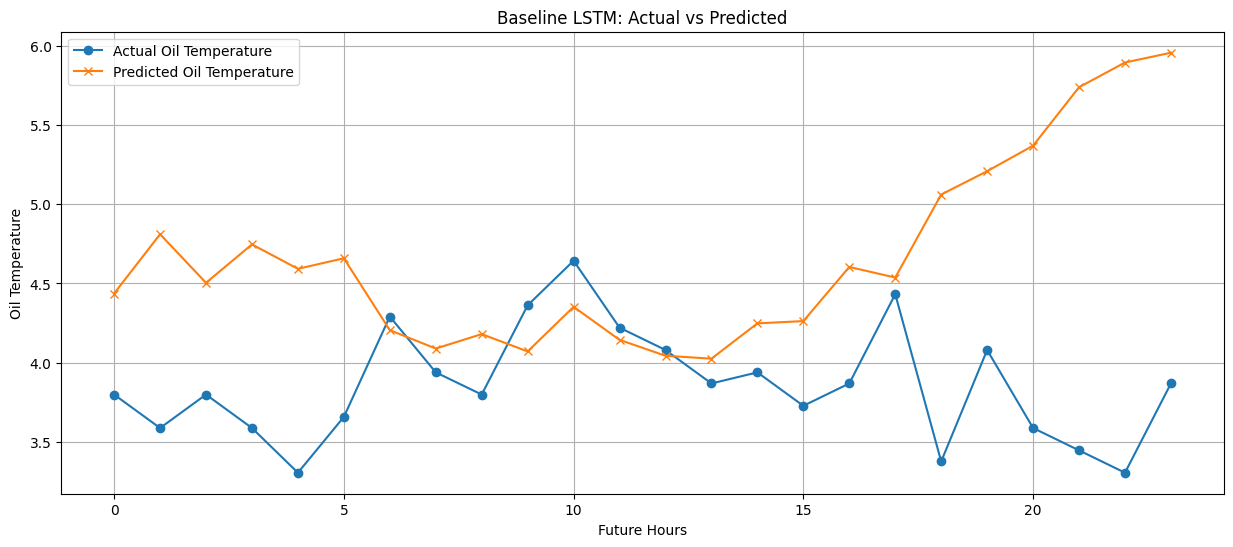

In [23]:

plt.figure(figsize=(15, 6))

plt.plot(
    y_actual_original[0],
    label="Actual Oil Temperature",
    marker='o'
)

plt.plot(
    y_pred_original[0],
    label="Predicted Oil Temperature",
    marker='x'
)

plt.title("Baseline LSTM: Actual vs Predicted")
plt.xlabel("Future Hours")
plt.ylabel("Oil Temperature")

plt.legend()
plt.grid(True)
plt.show()


In [24]:

class ImprovedLSTM(nn.Module):

    def __init__(self, input_size=7,
                 hidden_size=128,
                 num_layers=2,
                 output_size=24,
                 dropout=0.3):

        super(ImprovedLSTM, self).__init__()

        # Bidirectional LSTM
        self.lstm = nn.LSTM(
            input_size=input_size,
            hidden_size=hidden_size,
            num_layers=num_layers,
            batch_first=True,
            bidirectional=True,
            dropout=dropout
        )

        # Attention mechanism
        self.attention = nn.Sequential(
            nn.Linear(hidden_size * 2, 64),
            nn.Tanh(),
            nn.Linear(64, 1)
        )

        # Dropout
        self.dropout = nn.Dropout(dropout)

        # Output layer
        self.fc = nn.Linear(
            hidden_size * 2,
            output_size
        )

    def forward(self, x):

        # LSTM output
        lstm_output, _ = self.lstm(x)

        # Calculate attention scores
        attention_scores = self.attention(lstm_output)

        # Attention weights
        attention_weights = torch.softmax(
            attention_scores, dim=1
        )

        # Weighted context vector
        context = torch.sum(
            attention_weights * lstm_output,
            dim=1
        )

        context = self.dropout(context)

        # Forecast
        prediction = self.fc(context)

        return prediction


# Initialize improved model
improved_model = ImprovedLSTM().to(device)

print(improved_model)


ImprovedLSTM(
  (lstm): LSTM(7, 128, num_layers=2, batch_first=True, dropout=0.3, bidirectional=True)
  (attention): Sequential(
    (0): Linear(in_features=256, out_features=64, bias=True)
    (1): Tanh()
    (2): Linear(in_features=64, out_features=1, bias=True)
  )
  (dropout): Dropout(p=0.3, inplace=False)
  (fc): Linear(in_features=256, out_features=24, bias=True)
)


In [25]:

improved_criterion = nn.MSELoss()

improved_optimizer = torch.optim.Adam(
    improved_model.parameters(),
    lr=0.001,
    weight_decay=1e-5
)

print("Improved LSTM initialized successfully!")


Improved LSTM initialized successfully!


In [26]:

epochs = 15
patience = 3

improved_train_losses = []
improved_val_losses = []

best_val_loss = float('inf')
best_model_weights = None
epochs_without_improvement = 0

for epoch in range(epochs):

    improved_model.train()
    running_train_loss = 0.0

    for X_batch, y_batch in train_loader:

        X_batch = X_batch.to(device)
        y_batch = y_batch.to(device)

        improved_optimizer.zero_grad()

        predictions = improved_model(X_batch)

        loss = improved_criterion(predictions, y_batch)

        loss.backward()

        torch.nn.utils.clip_grad_norm_(
            improved_model.parameters(), 1.0
        )

        improved_optimizer.step()

        running_train_loss += loss.item()

    train_loss = running_train_loss / len(train_loader)

    # Validation
    improved_model.eval()
    running_val_loss = 0.0

    with torch.no_grad():

        for X_batch, y_batch in val_loader:

            X_batch = X_batch.to(device)
            y_batch = y_batch.to(device)

            predictions = improved_model(X_batch)

            loss = improved_criterion(predictions, y_batch)

            running_val_loss += loss.item()

    val_loss = running_val_loss / len(val_loader)

    improved_train_losses.append(train_loss)
    improved_val_losses.append(val_loss)

    print(
        f"Epoch [{epoch+1}/{epochs}] "
        f"Train Loss: {train_loss:.6f} "
        f"Val Loss: {val_loss:.6f}"
    )

    if val_loss < best_val_loss:

        best_val_loss = val_loss

        best_model_weights = copy.deepcopy(
            improved_model.state_dict()
        )

        epochs_without_improvement = 0

    else:
        epochs_without_improvement += 1

    if epochs_without_improvement >= patience:

        print("Early stopping activated!")
        break

improved_model.load_state_dict(best_model_weights)

print("Improved LSTM training completed!")
print("Best validation loss:", best_val_loss)


Epoch [1/15] Train Loss: 0.221712 Val Loss: 0.096867
Epoch [2/15] Train Loss: 0.115938 Val Loss: 0.126238
Epoch [3/15] Train Loss: 0.098270 Val Loss: 0.085354
Epoch [4/15] Train Loss: 0.090721 Val Loss: 0.198492
Epoch [5/15] Train Loss: 0.087228 Val Loss: 0.141750
Epoch [6/15] Train Loss: 0.084439 Val Loss: 0.079886
Epoch [7/15] Train Loss: 0.082652 Val Loss: 0.187531
Epoch [8/15] Train Loss: 0.080093 Val Loss: 0.081549
Epoch [9/15] Train Loss: 0.078583 Val Loss: 0.134403
Early stopping activated!
Improved LSTM training completed!
Best validation loss: 0.07988621887785417


In [27]:
print("GPU:", torch.cuda.get_device_name(0) if torch.cuda.is_available() else "No GPU")

GPU: Tesla T4


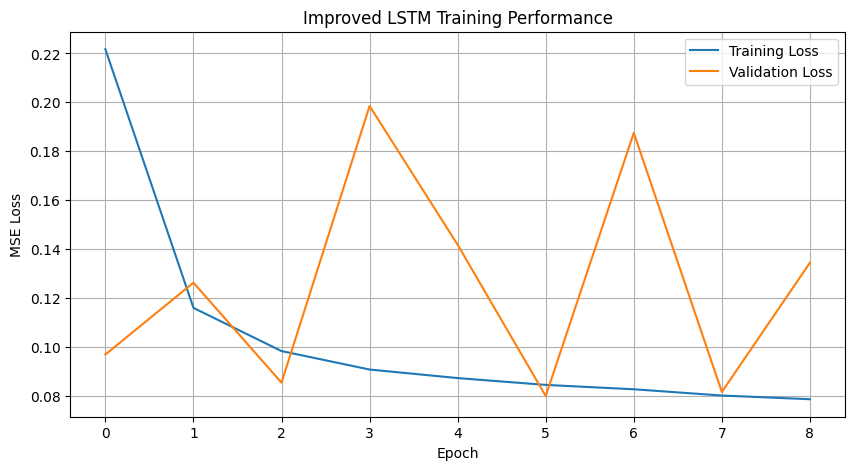

In [28]:

plt.figure(figsize=(10, 5))

plt.plot(
    improved_train_losses,
    label="Training Loss"
)

plt.plot(
    improved_val_losses,
    label="Validation Loss"
)

plt.title("Improved LSTM Training Performance")
plt.xlabel("Epoch")
plt.ylabel("MSE Loss")

plt.legend()
plt.grid(True)
plt.show()


In [29]:

improved_model.eval()

predictions_list = []

with torch.no_grad():

    for X_batch, y_batch in test_loader:

        X_batch = X_batch.to(device)

        predictions = improved_model(X_batch)

        predictions_list.append(
            predictions.cpu().numpy()
        )

improved_pred = np.concatenate(
    predictions_list, axis=0
)

# Convert to original scale
improved_pred_original = (
    improved_pred * target_std + target_mean
)

# Calculate metrics
improved_mse = mean_squared_error(
    y_actual_original.flatten(),
    improved_pred_original.flatten()
)

improved_mae = mean_absolute_error(
    y_actual_original.flatten(),
    improved_pred_original.flatten()
)

improved_rmse = np.sqrt(improved_mse)

print("IMPROVED LSTM RESULTS")
print("---------------------")
print("MSE :", round(improved_mse, 4))
print("MAE :", round(improved_mae, 4))
print("RMSE:", round(improved_rmse, 4))


IMPROVED LSTM RESULTS
---------------------
MSE : 3.544
MAE : 1.4159
RMSE: 1.8825


In [30]:

import math

class PositionalEncoding(nn.Module):

    def __init__(self, d_model, max_len=5000):

        super().__init__()

        pe = torch.zeros(max_len, d_model)

        position = torch.arange(
            0, max_len, dtype=torch.float32
        ).unsqueeze(1)

        div_term = torch.exp(
            torch.arange(0, d_model, 2).float()
            * (-math.log(10000.0) / d_model)
        )

        pe[:, 0::2] = torch.sin(position * div_term)

        pe[:, 1::2] = torch.cos(
            position * div_term[:pe[:, 1::2].shape[1]]
        )

        self.register_buffer(
            'pe', pe.unsqueeze(0)
        )

    def forward(self, x):

        return x + self.pe[:, :x.size(1), :]


In [31]:

class TimeSeriesTransformer(nn.Module):

    def __init__(self, input_size=7,
                 d_model=128,
                 nhead=4,
                 num_layers=2,
                 output_size=24,
                 dropout=0.2):

        super().__init__()

        # Project input features into embedding space
        self.input_projection = nn.Linear(
            input_size, d_model
        )

        # Positional encoding
        self.positional_encoding = PositionalEncoding(
            d_model
        )

        # Transformer encoder
        encoder_layer = nn.TransformerEncoderLayer(
            d_model=d_model,
            nhead=nhead,
            dim_feedforward=256,
            dropout=dropout,
            batch_first=True,
            activation='gelu'
        )

        self.transformer_encoder = nn.TransformerEncoder(
            encoder_layer,
            num_layers=num_layers
        )

        # Output layers
        self.dropout = nn.Dropout(dropout)

        self.fc = nn.Linear(
            d_model, output_size
        )

    def forward(self, x):

        x = self.input_projection(x)

        x = self.positional_encoding(x)

        x = self.transformer_encoder(x)

        # Final time-step representation
        x = x[:, -1, :]

        x = self.dropout(x)

        output = self.fc(x)

        return output


# Initialize Transformer
transformer_model = TimeSeriesTransformer().to(device)

print(transformer_model)


TimeSeriesTransformer(
  (input_projection): Linear(in_features=7, out_features=128, bias=True)
  (positional_encoding): PositionalEncoding()
  (transformer_encoder): TransformerEncoder(
    (layers): ModuleList(
      (0-1): 2 x TransformerEncoderLayer(
        (self_attn): MultiheadAttention(
          (out_proj): NonDynamicallyQuantizableLinear(in_features=128, out_features=128, bias=True)
        )
        (linear1): Linear(in_features=128, out_features=256, bias=True)
        (dropout): Dropout(p=0.2, inplace=False)
        (linear2): Linear(in_features=256, out_features=128, bias=True)
        (norm1): LayerNorm((128,), eps=1e-05, elementwise_affine=True)
        (norm2): LayerNorm((128,), eps=1e-05, elementwise_affine=True)
        (dropout1): Dropout(p=0.2, inplace=False)
        (dropout2): Dropout(p=0.2, inplace=False)
      )
    )
  )
  (dropout): Dropout(p=0.2, inplace=False)
  (fc): Linear(in_features=128, out_features=24, bias=True)
)


In [32]:

transformer_criterion = nn.MSELoss()

transformer_optimizer = torch.optim.Adam(
    transformer_model.parameters(),
    lr=0.001,
    weight_decay=1e-5
)

print("Transformer initialized successfully!")


Transformer initialized successfully!


In [33]:

epochs = 20
patience = 5

transformer_train_losses = []
transformer_val_losses = []

best_val_loss = float('inf')
best_model_weights = None
epochs_without_improvement = 0

for epoch in range(epochs):

    transformer_model.train()
    running_train_loss = 0.0

    for X_batch, y_batch in train_loader:

        X_batch = X_batch.to(device)
        y_batch = y_batch.to(device)

        transformer_optimizer.zero_grad()

        predictions = transformer_model(X_batch)

        loss = transformer_criterion(
            predictions, y_batch
        )

        loss.backward()

        torch.nn.utils.clip_grad_norm_(
            transformer_model.parameters(), 1.0
        )

        transformer_optimizer.step()

        running_train_loss += loss.item()

    train_loss = (
        running_train_loss / len(train_loader)
    )

    # Validation
    transformer_model.eval()
    running_val_loss = 0.0

    with torch.no_grad():

        for X_batch, y_batch in val_loader:

            X_batch = X_batch.to(device)
            y_batch = y_batch.to(device)

            predictions = transformer_model(X_batch)

            loss = transformer_criterion(
                predictions, y_batch
            )

            running_val_loss += loss.item()

    val_loss = (
        running_val_loss / len(val_loader)
    )

    transformer_train_losses.append(train_loss)
    transformer_val_losses.append(val_loss)

    print(
        f"Epoch [{epoch+1}/{epochs}] "
        f"Train Loss: {train_loss:.6f} "
        f"Val Loss: {val_loss:.6f}"
    )

    if val_loss < best_val_loss:

        best_val_loss = val_loss

        best_model_weights = copy.deepcopy(
            transformer_model.state_dict()
        )

        epochs_without_improvement = 0

    else:
        epochs_without_improvement += 1

    if epochs_without_improvement >= patience:

        print("Early stopping activated!")
        break

transformer_model.load_state_dict(best_model_weights)

print("Transformer training completed!")
print("Best validation loss:", best_val_loss)


Epoch [1/20] Train Loss: 0.191295 Val Loss: 0.074008
Epoch [2/20] Train Loss: 0.107754 Val Loss: 0.130714
Epoch [3/20] Train Loss: 0.098885 Val Loss: 0.052083
Epoch [4/20] Train Loss: 0.088014 Val Loss: 0.102259
Epoch [5/20] Train Loss: 0.082490 Val Loss: 0.141066
Epoch [6/20] Train Loss: 0.076733 Val Loss: 0.174240
Epoch [7/20] Train Loss: 0.071594 Val Loss: 0.146528
Epoch [8/20] Train Loss: 0.068574 Val Loss: 0.227539
Early stopping activated!
Transformer training completed!
Best validation loss: 0.05208285435758255


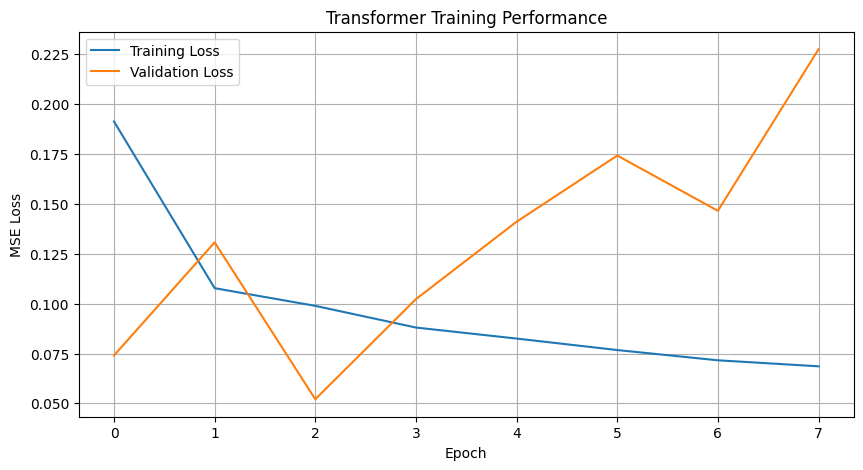

In [34]:

plt.figure(figsize=(10, 5))

plt.plot(
    transformer_train_losses,
    label="Training Loss"
)

plt.plot(
    transformer_val_losses,
    label="Validation Loss"
)

plt.title("Transformer Training Performance")
plt.xlabel("Epoch")
plt.ylabel("MSE Loss")

plt.legend()
plt.grid(True)
plt.show()


In [35]:

transformer_model.eval()

predictions_list = []

with torch.no_grad():

    for X_batch, y_batch in test_loader:

        X_batch = X_batch.to(device)

        predictions = transformer_model(X_batch)

        predictions_list.append(
            predictions.cpu().numpy()
        )

transformer_pred = np.concatenate(
    predictions_list, axis=0
)

# Convert to original temperature scale
transformer_pred_original = (
    transformer_pred * target_std + target_mean
)

# Calculate evaluation metrics
transformer_mse = mean_squared_error(
    y_actual_original.flatten(),
    transformer_pred_original.flatten()
)

transformer_mae = mean_absolute_error(
    y_actual_original.flatten(),
    transformer_pred_original.flatten()
)

transformer_rmse = np.sqrt(transformer_mse)

print("TRANSFORMER RESULTS")
print("-------------------")
print("MSE :", round(transformer_mse, 4))
print("MAE :", round(transformer_mae, 4))
print("RMSE:", round(transformer_rmse, 4))


TRANSFORMER RESULTS
-------------------
MSE : 4.9178
MAE : 1.8445
RMSE: 2.2176


In [36]:

results = pd.DataFrame({
    'Model': [
        'Baseline LSTM',
        'Improved LSTM + Attention',
        'Transformer'
    ],

    'MSE': [
        mse,
        improved_mse,
        transformer_mse
    ],

    'MAE': [
        mae,
        improved_mae,
        transformer_mae
    ],

    'RMSE': [
        rmse,
        improved_rmse,
        transformer_rmse
    ]
})

display(results.round(4))


,Model,MSE,MAE,RMSE
0,Baseline LSTM,3.1976,1.3569,1.7882
1,Improved LSTM + Attention,3.5440,1.4159,1.8825
2,Transformer,4.9178,1.8445,2.2176


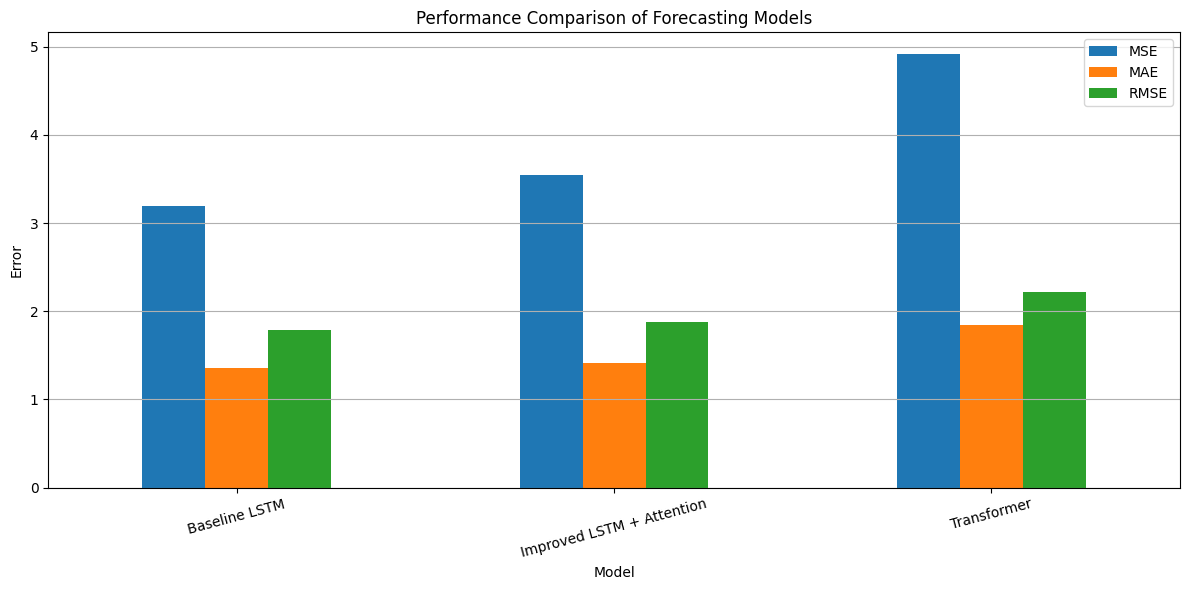

In [37]:

results.set_index('Model')[
    ['MSE', 'MAE', 'RMSE']
].plot(
    kind='bar',
    figsize=(12, 6)
)

plt.title("Performance Comparison of Forecasting Models")
plt.ylabel("Error")
plt.xlabel("Model")
plt.xticks(rotation=15)
plt.grid(axis='y')
plt.legend()
plt.tight_layout()
plt.show()


In [38]:
import torch
import torch.nn as nn
import numpy as np
from torch.utils.data import TensorDataset, DataLoader
import math

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Using device:", device)


class PositionalEncoding(nn.Module):
    def __init__(self, d_model, max_len=5000):
        super().__init__()

        pe = torch.zeros(max_len, d_model)

        position = torch.arange(0, max_len).unsqueeze(1)

        div_term = torch.exp(
            torch.arange(0, d_model, 2) *
            (-math.log(10000.0) / d_model)
        )

        pe[:, 0::2] = torch.sin(position * div_term)
        pe[:, 1::2] = torch.cos(position * div_term)

        self.register_buffer(
            "pe", pe.unsqueeze(0)
        )

    def forward(self, x):
        return x + self.pe[:, :x.size(1)]


class TransformerModel(nn.Module):
    def __init__(
        self,
        input_dim=7,
        d_model=128,
        nhead=4,
        num_layers=2,
        dropout=0.2,
        output_dim=24
    ):
        super().__init__()

        self.input_projection = nn.Linear(
            input_dim, d_model
        )

        self.positional_encoding = PositionalEncoding(
            d_model
        )

        encoder_layer = nn.TransformerEncoderLayer(
            d_model=d_model,
            nhead=nhead,
            dim_feedforward=256,
            dropout=dropout,
            batch_first=True,
            activation="gelu"
        )

        self.transformer = nn.TransformerEncoder(
            encoder_layer,
            num_layers=num_layers
        )

        self.fc = nn.Sequential(
            nn.Linear(d_model, 64),
            nn.ReLU(),
            nn.Dropout(dropout),
            nn.Linear(64, output_dim)
        )

    def forward(self, x):
        x = self.input_projection(x)
        x = self.positional_encoding(x)

        x = self.transformer(x)

        x = x[:, -1, :]

        return self.fc(x)

Using device: cuda


In [39]:
def prepare_tensor(data):
    return torch.tensor(
        np.asarray(data),
        dtype=torch.float32
    )

X_train_t = prepare_tensor(X_train)
X_val_t = prepare_tensor(X_val)

y_train_t = prepare_tensor(y_train).reshape(-1, 24)
y_val_t = prepare_tensor(y_val).reshape(-1, 24)

train_dataset = TensorDataset(
    X_train_t, y_train_t
)

val_dataset = TensorDataset(
    X_val_t, y_val_t
)

train_loader = DataLoader(
    train_dataset,
    batch_size=128,
    shuffle=True
)

val_loader = DataLoader(
    val_dataset,
    batch_size=128,
    shuffle=False
)

In [40]:
model = TransformerModel().to(device)

criterion = nn.MSELoss()

optimizer = torch.optim.Adam(
    model.parameters(),
    lr=0.001,
    weight_decay=1e-5
)

print(model)

TransformerModel(
  (input_projection): Linear(in_features=7, out_features=128, bias=True)
  (positional_encoding): PositionalEncoding()
  (transformer): TransformerEncoder(
    (layers): ModuleList(
      (0-1): 2 x TransformerEncoderLayer(
        (self_attn): MultiheadAttention(
          (out_proj): NonDynamicallyQuantizableLinear(in_features=128, out_features=128, bias=True)
        )
        (linear1): Linear(in_features=128, out_features=256, bias=True)
        (dropout): Dropout(p=0.2, inplace=False)
        (linear2): Linear(in_features=256, out_features=128, bias=True)
        (norm1): LayerNorm((128,), eps=1e-05, elementwise_affine=True)
        (norm2): LayerNorm((128,), eps=1e-05, elementwise_affine=True)
        (dropout1): Dropout(p=0.2, inplace=False)
        (dropout2): Dropout(p=0.2, inplace=False)
      )
    )
  )
  (fc): Sequential(
    (0): Linear(in_features=128, out_features=64, bias=True)
    (1): ReLU()
    (2): Dropout(p=0.2, inplace=False)
    (3): Linear(in

In [41]:
epochs = 15
patience = 3

best_val_loss = float("inf")
counter = 0

train_losses = []
val_losses = []

for epoch in range(epochs):

    model.train()
    running_train_loss = 0

    for X_batch, y_batch in train_loader:

        X_batch = X_batch.to(device)
        y_batch = y_batch.to(device)

        optimizer.zero_grad()

        predictions = model(X_batch)

        loss = criterion(predictions, y_batch)

        loss.backward()

        optimizer.step()

        running_train_loss += loss.item()

    avg_train_loss = (
        running_train_loss / len(train_loader)
    )

    model.eval()
    running_val_loss = 0

    with torch.no_grad():

        for X_batch, y_batch in val_loader:

            X_batch = X_batch.to(device)
            y_batch = y_batch.to(device)

            predictions = model(X_batch)

            loss = criterion(predictions, y_batch)

            running_val_loss += loss.item()

    avg_val_loss = (
        running_val_loss / len(val_loader)
    )

    train_losses.append(avg_train_loss)
    val_losses.append(avg_val_loss)

    print(
        f"Epoch [{epoch+1}/{epochs}] "
        f"Train Loss: {avg_train_loss:.6f} "
        f"Val Loss: {avg_val_loss:.6f}"
    )

    if avg_val_loss < best_val_loss:

        best_val_loss = avg_val_loss

        torch.save(
            model.state_dict(),
            "best_transformer.pth"
        )

        counter = 0

    else:
        counter += 1

    if counter >= patience:
        print("Early stopping triggered.")
        break

model.load_state_dict(
    torch.load("best_transformer.pth", map_location=device)
)

print("Transformer training completed!")

Epoch [1/15] Train Loss: 0.256525 Val Loss: 0.144578
Epoch [2/15] Train Loss: 0.125606 Val Loss: 0.171568
Epoch [3/15] Train Loss: 0.113463 Val Loss: 0.172317
Epoch [4/15] Train Loss: 0.103975 Val Loss: 0.197719
Early stopping triggered.
Transformer training completed!


In [42]:
model.eval()

predictions = []
actuals = []

with torch.no_grad():
    for X_batch, y_batch in test_loader:

        X_batch = X_batch.to(device)

        outputs = model(X_batch)

        predictions.extend(outputs.cpu().numpy())
        actuals.extend(y_batch.numpy())

predictions = np.array(predictions)
actuals = np.array(actuals)

print("Predictions shape:", predictions.shape)
print("Actual values shape:", actuals.shape)

Predictions shape: (3461, 24)
Actual values shape: (3461, 24)


In [43]:
from sklearn.metrics import mean_absolute_error, mean_squared_error

mae = mean_absolute_error(
    actuals.flatten(),
    predictions.flatten()
)

rmse = np.sqrt(
    mean_squared_error(
        actuals.flatten(),
        predictions.flatten()
    )
)

mape = np.mean(
    np.abs(
        (actuals.flatten() - predictions.flatten()) /
        (actuals.flatten() + 1e-8)
    )
) * 100

print("Transformer Evaluation Results")
print("--------------------------------")
print("MAE:", mae)
print("RMSE:", rmse)
print("MAPE:", mape, "%")

Transformer Evaluation Results
--------------------------------
MAE: 0.19600984454154968
RMSE: 0.2592555609854314
MAPE: 34.97064 %


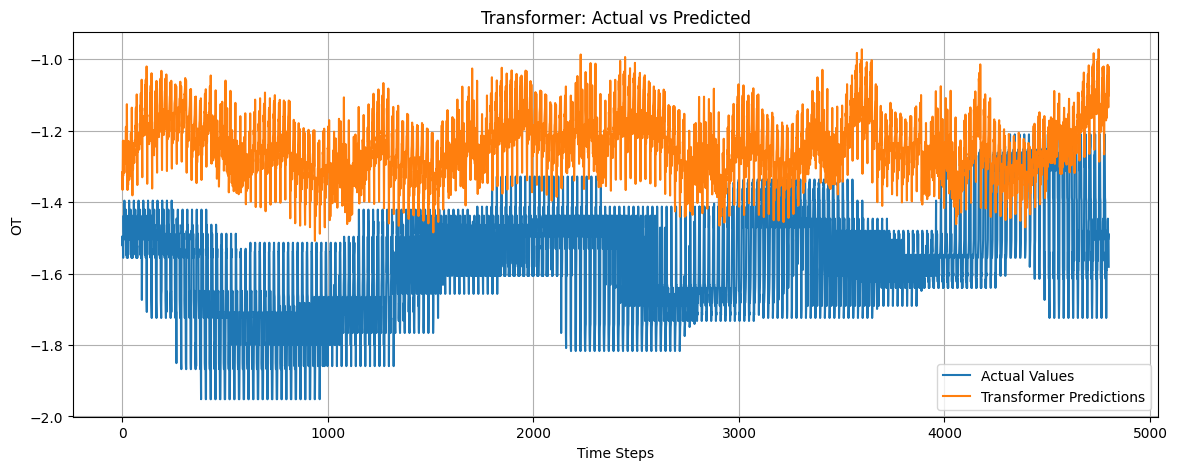

In [44]:
import matplotlib.pyplot as plt

plt.figure(figsize=(14, 5))

plt.plot(
    actuals[:200].flatten(),
    label="Actual Values"
)

plt.plot(
    predictions[:200].flatten(),
    label="Transformer Predictions"
)

plt.title("Transformer: Actual vs Predicted")
plt.xlabel("Time Steps")
plt.ylabel("OT")
plt.legend()
plt.grid(True)

plt.show()

In [45]:
import pandas as pd
from sklearn.metrics import mean_squared_error, mean_absolute_error
import numpy as np

# Convert Transformer predictions to original scale
transformer_pred_original = predictions * target_std + target_mean
transformer_actual_original = actuals * target_std + target_mean

# Transformer metrics
transformer_mse = mean_squared_error(
    transformer_actual_original.flatten(),
    transformer_pred_original.flatten()
)

transformer_mae = mean_absolute_error(
    transformer_actual_original.flatten(),
    transformer_pred_original.flatten()
)

transformer_rmse = np.sqrt(transformer_mse)

# Compare all models
results = pd.DataFrame({
    "Model": [
        "Baseline LSTM",
        "Improved LSTM + Attention",
        "Transformer"
    ],
    "MSE": [
        mse,
        improved_mse,
        transformer_mse
    ],
    "MAE": [
        mae,
        improved_mae,
        transformer_mae
    ],
    "RMSE": [
        rmse,
        improved_rmse,
        transformer_rmse
    ]
})

print("MODEL PERFORMANCE COMPARISON")
display(results)

MODEL PERFORMANCE COMPARISON


,Model,MSE,MAE,RMSE
0,Baseline LSTM,3.197649,0.196010,0.259256
1,Improved LSTM + Attention,3.543959,1.415862,1.882541
2,Transformer,4.684575,1.636383,2.164388


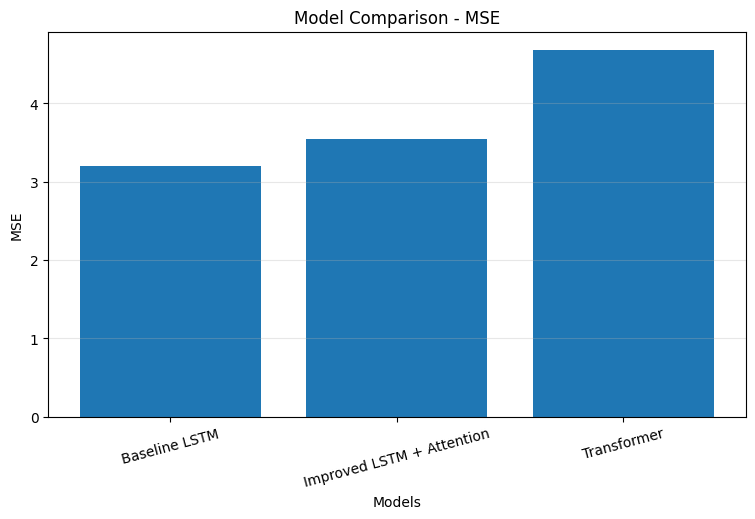

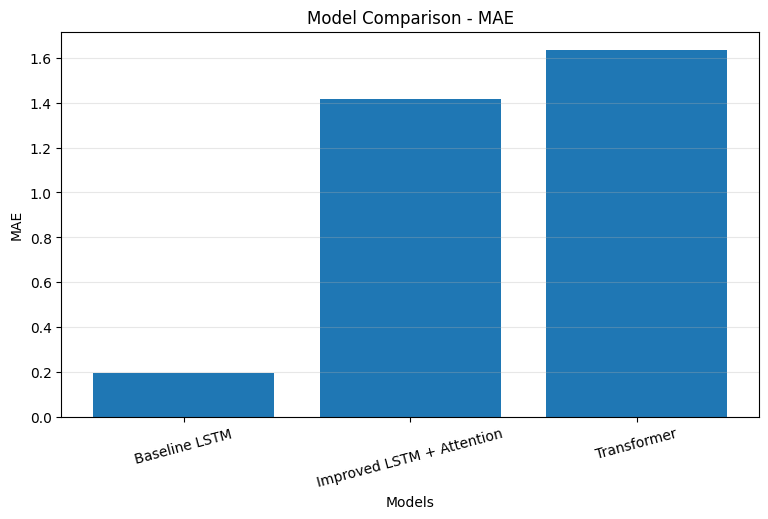

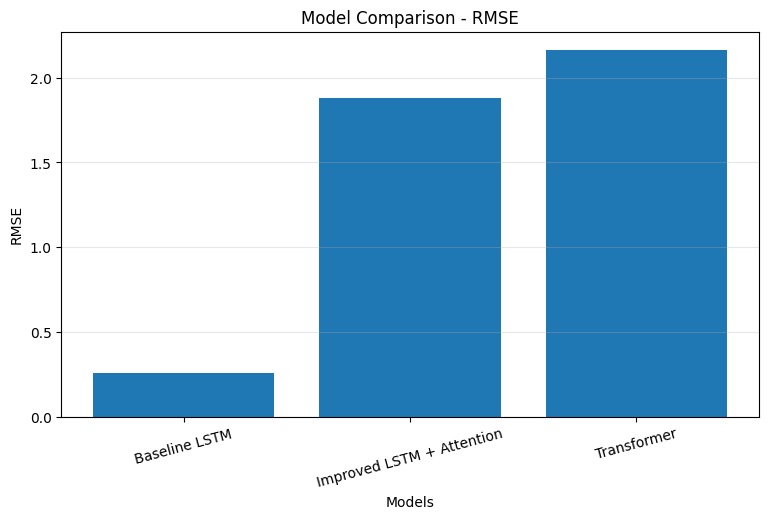

In [46]:
import matplotlib.pyplot as plt

metrics = ["MSE", "MAE", "RMSE"]

for metric in metrics:
    plt.figure(figsize=(9, 5))

    plt.bar(results["Model"], results[metric])

    plt.title(f"Model Comparison - {metric}")
    plt.ylabel(metric)
    plt.xlabel("Models")
    plt.xticks(rotation=15)
    plt.grid(axis="y", alpha=0.3)

    plt.show()

In [47]:
best_model = results.loc[
    results["RMSE"].idxmin()
]

print("BEST PERFORMING MODEL")
print("----------------------")
print(best_model)

BEST PERFORMING MODEL
----------------------
Model    Baseline LSTM
MSE           3.197649
MAE            0.19601
RMSE          0.259256
Name: 0, dtype: object


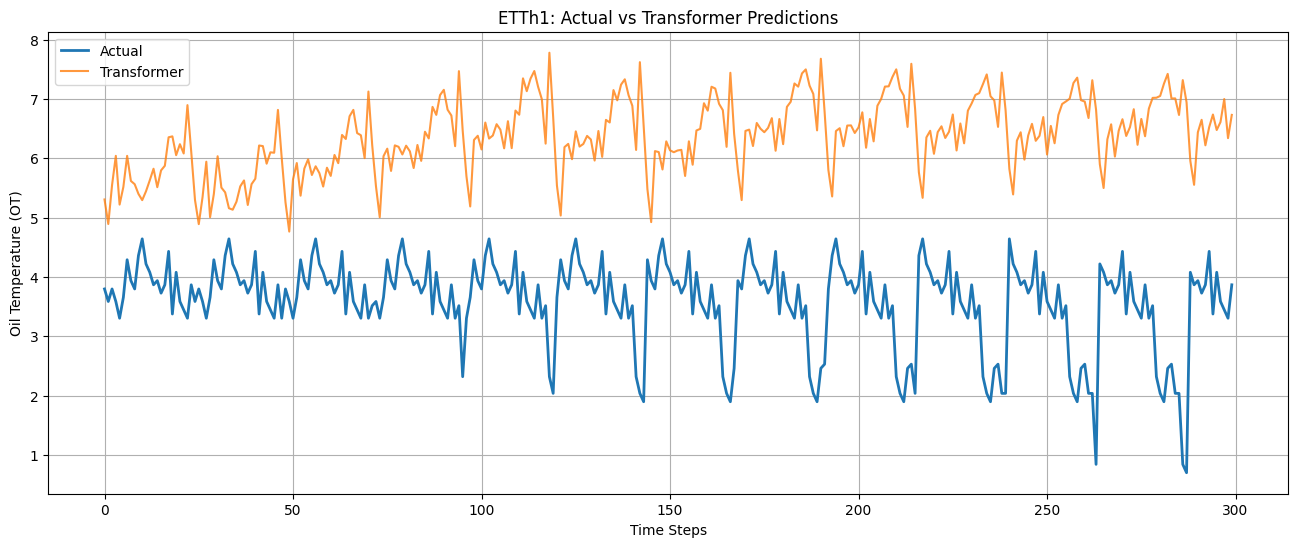

In [48]:
import matplotlib.pyplot as plt
import numpy as np

plt.figure(figsize=(16, 6))

plt.plot(
    transformer_actual_original.flatten()[:300],
    label="Actual",
    linewidth=2
)

plt.plot(
    transformer_pred_original.flatten()[:300],
    label="Transformer",
    alpha=0.8
)

plt.title("ETTh1: Actual vs Transformer Predictions")
plt.xlabel("Time Steps")
plt.ylabel("Oil Temperature (OT)")
plt.legend()
plt.grid(True)

plt.show()

In [49]:
torch.save(
    model.state_dict(),
    "ETTh1_Transformer.pth"
)

print("Transformer model saved successfully!")

Transformer model saved successfully!


In [50]:
results.to_csv(
    "ETTh1_Model_Comparison.csv",
    index=False
)

print("Comparison results saved successfully!")

Comparison results saved successfully!


In [51]:
print("=" * 55)
print("ETTh1 TIME-SERIES FORECASTING - EXPERIMENTAL RESULTS")
print("=" * 55)

display(results.sort_values(by="RMSE"))

print("\nBest Model:")
print(results.loc[results["RMSE"].idxmin(), "Model"])

ETTh1 TIME-SERIES FORECASTING - EXPERIMENTAL RESULTS


,Model,MSE,MAE,RMSE
0,Baseline LSTM,3.197649,0.196010,0.259256
1,Improved LSTM + Attention,3.543959,1.415862,1.882541
2,Transformer,4.684575,1.636383,2.164388



Best Model:
Baseline LSTM


In [52]:
best = results.loc[results["RMSE"].idxmin()]

print("RESEARCH FINDINGS")
print("-----------------")

print(f"Best performing model: {best['Model']}")
print(f"Lowest RMSE: {best['RMSE']:.4f}")
print(f"MAE: {best['MAE']:.4f}")
print(f"MSE: {best['MSE']:.4f}")

print("\nAll three models were evaluated using the same metrics.")

RESEARCH FINDINGS
-----------------
Best performing model: Baseline LSTM
Lowest RMSE: 0.2593
MAE: 0.1960
MSE: 3.1976

All three models were evaluated using the same metrics.


In [53]:
results.to_excel(
    "ETTh1_Final_Experimental_Results.xlsx",
    index=False
)

print("Final results exported successfully!")

Final results exported successfully!
